# Deep Learning (DL)
---

## ¿Qué es?

* Es una de las técnicas utilizadas en ML
* Dentro de ML (aprender de los datos)
* Se busca extraer características/patrones de datos sin procesar, utilizando diferentes capas
* Objetivo: identificar aspectos mas representativos y relevantes de los datos
* ML aplica en DL
* RNA simula el proceso de toma de decisión del cerebro humano
* Hablamos de RNA (capas, función de activación, etc.)

## RNA

* Un modelo de ML **inspirado** en el funcionamiento de las redes neuronales biológicas del cerebro
* Entender como funciona una simple neurona, el **perceptrón** (unidad de cómputo)
* Entradas/características con sus pesos -> sumar -> función de activación $\theta$ -> output $\hat y$
* Entradas y salidas son numéricas $(x_j)$
* Cada entrada tiene asociado un peso $(w_j)$
* output se valida con el output real, de acuerdo a esa diferencia es la entrada a un nuevo algoritmo para actualizar los pesos
* Se actualizan los pesos fila a fila del dataset y ajustan constantemente en la fase entrenamiento
* Función de activación quita linealidad, logrando aprender de patrones complejos

$$\hat y = \theta(\Sigma_{j=1}^d x_jw_j)$$

## Funciones de activación

* **Función Sigmoidea**
    * Si valor es grande es cercano a 1
    * Si valor es chico es cercano a 0
    * Sirve para clasificación binaria
    * Se va a obtener un valor entre 0 y 1 en las predicciones
    * Si la salida es menor que 0.5 no es spam caso contrario es spam

$$f(x) = \dfrac{1}{1 + e^{-x}}$$

* **Función Tangente Hiperbólica**
    * Si valor es grande es cercano a 1
    * Si valor es chico es carcano a -1
    * Si valor muy cerca a 0 entonces dá 0
    * También sirve para clasificación binaria
    * Se va a obtener un valor entre -1 y 1

$$f(x) = \dfrac{e^x - e^{-x}}{e^x + e^{-x}}$$

* **Función ReLu - Rectified Linear Unit**
    * Valores >= 0 devuelve el valor
    * Valores < devuelve 0
    * Permite sesgar de una forma buena
    * Sirve para capas intermedias (ocultas)

$$f(x) = max(0, x)$$

* **SoftMax**
    * Sirve para clasificación multiclase
    * Devuelve una distribución de probabilidades que representa la cercanía a cada categoría/clase
    * La suma de todas las probabilidades es 1

$$softmax(x_i) = \dfrac{e^{x_i}}{\Sigma_j e^{x_j}}$$

## Funciones de pérdida

* Para constrastar el valor predecido con el real
* A partir de esto utilizar el algoritmo Descenso Gradiente para actualizar los pesos de la neurona
* **Regresión**
    * MSE (Error cuadrático medio)
    * Error cuadrático medio logarítmico
    * Error absoluto medio
* **Clasificación binaria**
    * Entropia Cruzada Binaria
    * Hinge
    * Squared Hinge
* **Clasificación multiclase**
    * Sparse Multiclass Cross-Entropy Loss
    * Kullback Leibler Divergence Loss

## Implementación de una neurona

* Librerias de Python:
    * Tensorflow
    * PyTorch
    * Keras API (capa de abstracción por encima de Tensorflow y PyTorch)

## Reglas

* **Cant de neuronas de la capa de entrada** queda determinada por la cantidad de características elegidas del dataset
* **Cant de neuronas en la salida** está relacionada con los datos a estimar. Para clasificación binaria, la cantidad de neuronas de salida es 1 (sigmoidea)

## Ejemplo: regresión lineal

In [24]:
import tensorflow as tf

In [25]:
# 1 neurona, con activación lineal y entrada 1
model = tf.keras.Sequential([tf.keras.layers.Dense(1, activation="linear", input_shape=(1, )), ])

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
import pandas as pd

In [27]:
train = pd.read_csv('train.csv')
train.head()

,x,y
0,24,21.549452
1,50,47.464463
2,15,17.218656
3,38,36.586398
4,87,87.288984


In [28]:
test = pd.read_csv('test.csv')
test.head()

,x,y
0,77,79.775152
1,21,23.177279
2,22,25.609262
3,20,17.857388
4,36,41.849864


In [29]:
#spliteo caracterisiticas. entrada x
#spliteo target. salida
train_x = train.drop("y",axis="columns")
train_y = train.drop("x", axis="columns")
train_y

,y
0,21.549452
1,47.464463
2,17.218656
3,36.586398
4,87.288984
...,...
694,58.595006
695,94.625094
696,88.603770
697,63.648685


In [30]:
test_x = test.drop("y", axis="columns")
test_y = test.drop("x", axis="columns")

In [31]:
# para normalizar los datos de entrada a valores muy chicos entre 0 y 1
from sklearn.preprocessing import normalize

train_x = normalize(train_x, axis=0)

In [32]:
# compilar el modelo con función de pérdida mse (error cuadrático medio)
model.compile(loss="mse")

In [33]:
# epochs son las iteraciones
model.fit(train_x, train_y, epochs=200)

Epoch 1/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3334.6885  
Epoch 2/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3332.1660 
Epoch 3/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3329.8767 
Epoch 4/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3327.5894 
Epoch 5/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3325.3062 
Epoch 6/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3323.0354 
Epoch 7/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3320.7715 
Epoch 8/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3318.5054 
Epoch 9/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3316.2292 
Epoch 10/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3313.9617 
Epoch 11/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3311.6792 
Epoch 12/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3309.4185 
Epoch 13/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3307.1609 
Epoch 14/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3304.8777 
Epoch 15/200
2

In [34]:
# You can also inspect the learned weights and bias
weights, bias = model.layers[0].get_weights()
print(f"Learned weight: {weights[0][0]:.2f}")
print(f"Learned bias: {bias[0]:.2f}")

Learned weight: 5.18
Learned bias: 4.38


In [35]:
predicciones = model.predict(test_x)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [37]:
#armo df con predicciones
df_pred = pd.DataFrame(data=predicciones)
df_pred.rename(columns={0:"y"},inplace=True)
df_pred = df_pred.join(test_x)

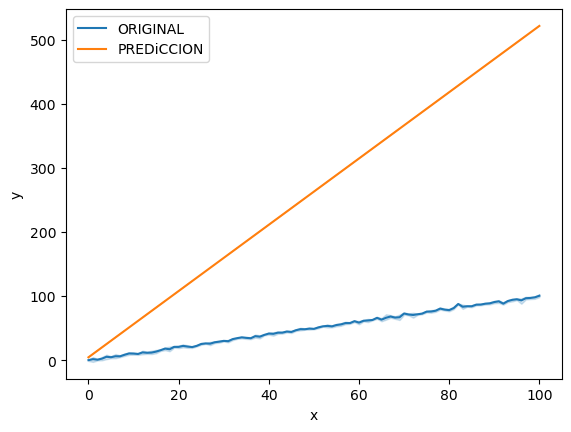

In [39]:
import seaborn as sb
import matplotlib.pyplot as plt

sb.lineplot(data=train, x="x", y="y", label='ORIGINAL')
sb.lineplot(data=df_pred, x="x", y="y", label='PREDiCCION')
plt.legend()
plt.show()

## Ejemplo: clasificación

In [52]:
model = tf.keras.Sequential([tf.keras.layers.Dense(1, activation="sigmoid", input_shape=(3, )), ])

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [53]:
data = pd.read_csv('Kyphosis.csv', sep=";")
data.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [54]:
mapeo = {"absent":0, "present":1}
data['Kyphosis'] = data['Kyphosis'].map(mapeo)

In [55]:
x = data.drop(columns=["Kyphosis"], axis="columns")
y = data.drop(columns=["Age", "Number", "Start"], axis="columns")

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [57]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

In [58]:
model.compile(optimizer="adam", metrics=["accuracy"], loss="binary_crossentropy")

In [59]:
history = model.fit(x_train, y_train, epochs=300)

Epoch 1/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6094 - loss: 16.4170 
Epoch 2/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6094 - loss: 16.3858
Epoch 3/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6094 - loss: 16.3474
Epoch 4/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6094 - loss: 16.3128
Epoch 5/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6094 - loss: 16.2732
Epoch 6/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6094 - loss: 16.2366
Epoch 7/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6094 - loss: 16.2033
Epoch 8/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6094 - loss: 16.1629
Epoch 9/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6094 - loss: 16.1316
Epoch 10/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6094 - loss: 16.0942 
Epoch 11/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6094 - loss: 16.0550
Epoch 12/300
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy

In [60]:
loss, accuracy = model.evaluate(x_test, y_test)
accuracy

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5882 - loss: 6.9676


0.5882353186607361

In [61]:
salida = model.predict(x_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


In [62]:
predicted_classes = (salida > 0.5).astype(int)
print("Predicted classes:\n", predicted_classes)

Predicted classes:
 [[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]]


In [63]:
y_test

,Kyphosis
10,1
61,1
35,0
17,0
8,0
37,1
75,0
72,0
77,0
66,0
